# 05 · Optimización final del modelo

**Grupo:** Oscar Romero Quincoces · Fernando Dapena Tauste · Daniel Garcia Lopez

**Objetivo.** El 04 cerró el modelo final: el **XGBoost de profundidad 3 del 03**, porque añadirle los scores del 02 no mejoraba. Antes de consolidar la entrega queda una pregunta: **¿se puede exprimir algo más de AUPR con el mismo tipo de modelo?** Aquí probamos las mejoras habituales de un clasificador de este tipo: promediar semillas, ajustar los hiperparámetros, otros modelos de boosting, variables nuevas y mezclas de modelos.

**Referencia a batir (04, D-2.7):** XGBoost d3 (400 árboles, `learning_rate` 0,05, `subsample` 0,8, `colsample_bytree` 0,7), **0,865 ± 0,061 en CV** y 0,815 en test.

**El riesgo de este notebook es engañarnos con el ruido.** Con 206 fraudes en train, cambiar solo la semilla mueve la AUPR de un fold varias milésimas. Si se prueban muchas variantes, alguna "ganará" por azar. Por eso:

1. Se amplía la validación a **3 particiones × 5 folds = 15 folds**: la oficial del 01 y dos más, también por grupos de duplicados.
2. Se mide el **ruido de semilla** con el mismo modelo y distintas semillas (un placebo) antes de mirar ningún candidato.
3. La **regla de decisión se fija en §1**, antes de ver los resultados, y el test no se mira hasta que la elección está cerrada (§9).

**Cómo leer este notebook.** Como el 01–04: **pregunta → tabla/figura → conclusión → impacto**.

| Parte I · Candidatos | Parte II · Comparación y entrega |
|---|---|
| 0. Setup | 7. ¿Qué gana en CV? |
| 1. ¿Cómo medimos una mejora pequeña? | 8. ¿Qué modelo elegimos antes del test? |
| 2. ¿Sirve promediar semillas o ir más despacio? | 9. ¿Se confirma en test? |
| 3. ¿Mejora ajustando los hiperparámetros? | 10. ¿Qué pasa con las copias exactas de fraudes? |
| 4. ¿Y otros modelos de árboles? | 11. Reentrenar y exportar producción |
| 5. ¿Ayudan variables nuevas? | 12. Conclusiones |
| 6. ¿Ayuda mezclar modelos? | |

**Resultado esperado del trabajo:** saber si alguna variante mejora de forma consistente al XGBoost del 04. Si ninguna lo hace, se mantiene el entregable del 04. Si alguna lo hace, se regenera `scores_produccion.csv` y el del 04 se guarda como respaldo.

In [1]:
# ============================================================
# CELDA COMÚN v2 — NO MODIFICAR (idéntica en 02, 03, 04 y 99)
# Lee el dataset preparado en 01: split fijo, folds por grupo y features. Ver D-0.1, D-1.1–D-1.4.
# Uso: m = fit(modelo, X_train, y_train); report("x", score(m, X_test)); cv_aupr(modelo); save_submission(score(m, X_prod))
# ============================================================
import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import clone, is_classifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.metrics import average_precision_score, roc_auc_score, precision_recall_curve

pd.options.display.max_columns = None
SEED = 42
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
OUTPUT_DIR = ROOT / "data" / "output"
PREP_CSV = Path(os.environ.get("PREP_CSV", OUTPUT_DIR / "01_dataset_preparado.csv"))
if not PREP_CSV.exists():
    raise FileNotFoundError(f"No existe {PREP_CSV}: ejecuta antes notebooks/01_EDA_y_preprocesado.ipynb")

FEAT_RAW = [f"X{i}" for i in range(1, 21)] + ["Amount"]
df = pd.read_csv(PREP_CSV)
df[FEAT_RAW] = df[FEAT_RAW].astype(float)  # el CSV guarda X enteras: se leen como float, igual que los originales
df_const = df[df["split"] != "prod"].sort_values("row_id").reset_index(drop=True)
df_prod = df[df["split"] == "prod"].sort_values("row_id").reset_index(drop=True)
FEATURES = [f"X{i}" for i in range(1, 21)] + ["log1p_Amount", "amount_freq"]  # conjunto por defecto (D-1.2)

tr, te = df_const[df_const["split"] == "train"], df_const[df_const["split"] == "test"]
X_train, y_train, groups_train = tr[FEATURES], tr["Class"].astype(int), tr["group_id"]
X_test, y_test = te[FEATURES], te["Class"].astype(int)
X_prod = df_prod[FEATURES]
dup_test = te["dup_en_train"].to_numpy(bool)  # filas de test con copia exacta en train (D-1.1)
# Folds por grupo hechos en 01 → (idx_train, idx_val) posicionales sobre X_train; vale como cv= en sklearn
cv_splits = [(np.flatnonzero(tr["fold"].to_numpy() != k), np.flatnonzero(tr["fold"].to_numpy() == k)) for k in range(5)]

def make_pipe(model, scaler="standard"):
    """Escalador ('standard' | 'robust' | None) + modelo: el escalado se ajusta DENTRO de cada fold."""
    steps = {"standard": [StandardScaler()], "robust": [RobustScaler()], None: []}[scaler]
    return make_pipeline(*steps, model)

def score(model, X):
    """Mayor = más fraude. Clasificador: predict_proba[:, 1] (o decision_function). No supervisado: −score_samples."""
    if not is_classifier(model):
        return -model.score_samples(X)  # GMM: −log-verosimilitud; IF / OCSVM / LOF(novelty=True): −normalidad
    return model.predict_proba(X)[:, 1] if hasattr(model, "predict_proba") else model.decision_function(X)

def fit(model, X, y):
    """Copia limpia ajustada: clasificador con (X, y); no supervisado SOLO con las normales (y == 0)."""
    y = np.asarray(y)
    return clone(model).fit(X, y) if is_classifier(model) else clone(model).fit(X[y == 0])

def metrics(y_true, scores):
    """Métrica oficial: AUPR (average_precision_score). Mayor score = más fraude."""
    return {"aupr": average_precision_score(y_true, scores), "roc_auc": roc_auc_score(y_true, scores)}

def cv_aupr(model, X=X_train, y=y_train):
    """AUPR por fold sobre cv_splits (clasificadores y no supervisados). Devuelve (media, std, scores OOF alineados con X)."""
    X, y, oof, auprs = np.asarray(X, dtype=float), np.asarray(y), np.zeros(len(y)), []
    assert len(X) == len(tr), "X debe tener las filas de X_train en su orden"
    for it, iv in cv_splits:
        oof[iv] = score(fit(model, X[it], y[it]), X[iv])
        auprs.append(average_precision_score(y[iv], oof[iv]))
    print(f"CV AUPR = {np.mean(auprs):.4f} ± {np.std(auprs):.4f}")
    return np.mean(auprs), np.std(auprs), oof

def report(name, s_test):
    """AUPR de test con y sin las filas duplicadas de train (D-1.1), y ROC-AUC."""
    s, y = np.asarray(s_test, dtype=float), y_test.to_numpy()
    assert len(s) == len(y), f"{len(s)} scores != {len(y)} filas de test"
    r = {"modelo": name, **metrics(y, s), "aupr_sin_dup": average_precision_score(y[~dup_test], s[~dup_test])}
    print(f"{name}: AUPR test={r['aupr']:.4f} | sin dup={r['aupr_sin_dup']:.4f} | ROC-AUC={r['roc_auc']:.4f}")
    return r

def plot_pr(y_true, scores_by_model, ax=None):
    ax = ax or plt.subplots(figsize=(6, 5))[1]
    for name, s in scores_by_model.items():
        p, r, _ = precision_recall_curve(y_true, s)
        ax.plot(r, p, label=f"{name} (AUPR={average_precision_score(y_true, s):.3f})")
    ax.axhline(np.mean(y_true), ls="--", c="grey", label="aleatorio")
    ax.set(xlabel="Recall", ylabel="Precision", title="Curva Precision-Recall")
    ax.legend()
    return ax

def save_submission(scores, name="scores_produccion"):
    """Entregable: CSV de UNA columna `score`, una fila por transacción de producción (mismo orden)."""
    scores = np.asarray(scores, dtype=float).ravel()
    assert len(scores) == len(df_prod) == 113_923, f"{len(scores)} scores, {len(df_prod)} filas de producción"
    assert np.isfinite(scores).all(), "hay scores no finitos"
    pd.DataFrame({"score": scores}).to_csv(OUTPUT_DIR / f"{name}.csv", index=False)

print(f"train {X_train.shape} fraudes={y_train.sum()} | test {X_test.shape} fraudes={y_test.sum()} "
      f"(dup={dup_test.sum()}) | prod {X_prod.shape} | folds={[len(v) for _, v in cv_splits]}")

train (119618, 22) fraudes=206 | test (51266, 22) fraudes=89 (dup=1643) | prod (113923, 22) | folds=[23924, 23924, 23923, 23924, 23923]


## 0. Setup

Librerías y utilidades propias de este notebook. Los datos, los cinco folds oficiales y `fit()`, `score()`, `report()` y `save_submission()` vienen de la **celda común v2, sin modificar**. Se mantienen gris = normal, rojo = fraude y morado = la referencia de boosting.

Además de las librerías del 03–04, este notebook usa **CatBoost** (otro boosting) y **Optuna** (búsqueda de hiperparámetros); están en `requirements.txt`.

In [2]:
import json
import hashlib
import platform
import shutil
import time
import warnings
import contextlib, io
import seaborn as sns
import scipy
import sklearn
from scipy import stats
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.ensemble import RandomForestClassifier
import xgboost as xgb
import lightgbm as lgb
import catboost as cb
import optuna
from IPython.display import display

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)
optuna.logging.set_verbosity(optuna.logging.WARNING)
sns.set_theme(style="whitegrid", context="notebook", rc={"figure.figsize": (8, 4.5), "axes.titleweight": "bold"})
C = {0: "#9e9e9e", 1: "#d62728"}          # gris = normal, rojo = fraude (como en 01–04)
LBL = {0: "normal", 1: "fraude"}
FAM = {"referencia": "#8172b3", "placebo": "#bdbdbd", "semillas": "#4c72b0", "ajuste fino": "#dd8452",
       "otro modelo": "#55a868", "variables": "#da8bc3", "mezcla": "#c44e52"}
N_JOBS = os.cpu_count() or 2
VERSIONES = {"python": platform.python_version(), "numpy": np.__version__, "pandas": pd.__version__,
             "scikit-learn": sklearn.__version__, "scipy": scipy.__version__, "xgboost": xgb.__version__,
             "lightgbm": lgb.__version__, "catboost": cb.__version__, "optuna": optuna.__version__}
CACHE_DIR = ROOT / ".cache" / "05_optimizacion"
CACHE_DIR.mkdir(parents=True, exist_ok=True)

XGB = lambda **kw: xgb.XGBClassifier(**{**dict(n_estimators=400, learning_rate=.05, max_depth=3, subsample=.8,
                                              colsample_bytree=.7, n_jobs=N_JOBS, random_state=SEED), **kw})
XGB_FINAL = XGB()   # configuración congelada del 03–04 (D-2.5, D-2.7)

Xa, ya, ga = X_train.to_numpy(float), y_train.to_numpy(), groups_train.to_numpy()
y_te = y_test.to_numpy()
y_cons = df_const["Class"].astype(int).to_numpy()
pd.Series(VERSIONES, name="versión").to_frame()

,versión
python,3.13.14
numpy,2.3.3
pandas,2.3.2
scikit-learn,1.8.0
scipy,1.16.2
xgboost,3.2.0
lightgbm,4.7.0
catboost,1.2.10
optuna,5.0.0


In [3]:
# Tres particiones de 5 folds por grupo: la 0 es la oficial del 01 (cv_splits); la 1 y la 2, nuevas.
REPS = 3
PARTICIONES = [cv_splits]
for s in (1, 2):
    sgkf = StratifiedGroupKFold(5, shuffle=True, random_state=s)
    PARTICIONES.append([(it, iv) for it, iv in sgkf.split(Xa, ya, ga)])
for p in PARTICIONES:
    assert sorted(np.concatenate([iv for _, iv in p])) == list(range(len(ya)))   # cada fila valida una vez
    assert all(not np.intersect1d(ga[it], ga[iv]).size for it, iv in p)          # ningún grupo cruza

RES, OOF, FAMILIA = {}, {}, {}   # nombre → AUPR (3 × 5) · scores OOF (3 × filas de train) · familia

def registrar(nombre, familia, oof, segundos):
    a = np.array([[average_precision_score(ya[iv], oof[r, iv]) for _, iv in PARTICIONES[r]] for r in range(REPS)])
    RES[nombre], OOF[nombre], FAMILIA[nombre] = {"a": a, "segundos": segundos}, oof, familia
    print(f"{nombre}: AUPR 15 folds = {a.mean():.4f} ± {a.std():.4f} | oficial = {a[0].mean():.4f} ({segundos:.0f} s)")

def evaluar(nombre, modelo, familia, X=None):
    """CV con las 3 particiones: ajusta con fit() de la celda común y guarda AUPR por fold y scores OOF."""
    X, t0, oof = Xa if X is None else X, time.time(), np.full((REPS, len(ya)), np.nan)
    for r, p in enumerate(PARTICIONES):
        for it, iv in p:
            oof[r, iv] = score(fit(modelo, X[it], ya[it]), X[iv])
    registrar(nombre, familia, oof, time.time()-t0)

def rango(s):
    return stats.rankdata(s) / len(s)

def combinar(nombre, componentes, familia, como="rango"):
    """Mezcla fold a fold: media de rangos (modelos distintos) o de probabilidades (mismo modelo, semillas distintas)."""
    oof = np.full((REPS, len(ya)), np.nan)
    for r, p in enumerate(PARTICIONES):
        for _, iv in p:
            ss = [OOF[c][r, iv] for c in componentes]
            oof[r, iv] = np.mean([rango(s) for s in ss] if como == "rango" else ss, axis=0)
    registrar(nombre, familia, oof, sum(RES[c]["segundos"] for c in componentes))

def delta(n, ref=None):
    return RES[n]["a"] - RES[ref or REF]["a"]

def tabla(nombres=None, ref=None):
    filas = {}
    for n in nombres or list(RES):
        a, d = RES[n]["a"], delta(n, ref)
        filas[n] = {"familia": FAMILIA[n], "media 15 folds": a.mean(), "std": a.std(), "oficial (5 folds)": a[0].mean(),
                    "Δ medio": d.mean(), "Δ particiones 1–2": d[1:].mean(), "peor Δ fold": d.min(),
                    "gana (de 15)": int((d > 0).sum()), "segundos": RES[n]["segundos"]}
    t = pd.DataFrame(filas).T
    return t.astype({c: float for c in t.columns if c != "familia"}).sort_values("media 15 folds", ascending=False)

def plot_deltas(nombres, title, ax=None, ref=None):
    """Δ AUPR frente a la referencia en cada uno de los 15 folds (marcador = partición) y su media (rombo)."""
    ax = ax or plt.subplots(figsize=(max(7, 1.3*len(nombres)), 4.6))[1]
    for i, n in enumerate(nombres):
        d = delta(n, ref)
        for r, mk in enumerate("os^"):
            ax.scatter(i + np.linspace(-.18, .18, 5), d[r], marker=mk, s=22, c="grey", alpha=.7,
                       label=f"partición {r}" if i == 0 else None)
        ax.scatter(i, d.mean(), marker="D", s=80, c=FAM[FAMILIA[n]], zorder=3, edgecolor="black")
        ax.annotate(f"{d.mean():+.4f}", (i, d.mean()), xytext=(12, 0), textcoords="offset points", va="center", fontsize=9)
    ax.axhline(0, c="black", lw=1)
    ax.axhline(MIN_MEJORA, c=FAM["referencia"], ls="--", lw=1, label=f"mejora mínima (+{MIN_MEJORA})")
    ax.set_xticks(range(len(nombres)), nombres, rotation=15, ha="right")
    ax.set(ylabel=f"Δ AUPR frente a {ref or REF}", title=title)
    ax.legend(fontsize=8, loc="lower left")
    return ax

pd.DataFrame({f"partición {r}": [int(ya[iv].sum()) for _, iv in p] for r, p in enumerate(PARTICIONES)},
             index=[f"fold {k}" for k in range(5)]).T.rename_axis("fraudes de validación")

,fold 0,fold 1,fold 2,fold 3,fold 4
fraudes de validación,,,,,
partición 0,41,41,41,42,41
partición 1,41,42,41,41,41
partición 2,42,41,41,41,41


---
# PARTE I · CANDIDATOS

Primero se fija cómo distinguir una mejora del ruido (§1). Después, de menos a más cambio respecto a la referencia: el mismo modelo con más semillas o más despacio (§2), sus hiperparámetros (§3), otros modelos de árboles (§4), variables nuevas (§5) y mezclas (§6).

## 1. ¿Cómo medimos una mejora pequeña?

**Qué miramos y por qué.** Las mejoras que se pueden esperar a estas alturas son de milésimas, del mismo orden que el ruido. Antes de mirar ningún candidato medimos ese ruido con un **placebo**: el mismo XGBoost con cuatro semillas distintas (43–46). Ninguna semilla es mejor que otra, así que sus diferencias con la semilla 42 son ruido puro. Todo se mide en **15 folds** (3 particiones × 5), siempre los mismos para todos los modelos, y se comparan **diferencias por pares fold a fold**.

**Regla de decisión (fijada aquí, antes de ver ningún candidato).** Un candidato sustituye a la referencia solo si cumple las tres condiciones:

1. **Δ medio ≥ +0,005** de AUPR en los 15 folds, la misma mejora mínima del 04.
2. **Gana en ≥ 11 de los 15 folds** (≈ 3 de cada 4, el equivalente al "4 de 5" del 04).
3. **Su Δ medio supera el mayor Δ medio de los placebos** (en valor absoluto): una mejora menor que la que da cambiar la semilla no es una mejora.

Si hay varios, se elige el de mayor Δ medio. Si ninguno cumple, se mantiene el XGBoost del 04. Para el modelo ajustado con Optuna (§3), que se busca sobre la partición oficial, se exige además Δ ≥ +0,005 **solo en las particiones 1–2**, que la búsqueda no ha visto.

In [4]:
MIN_MEJORA, MIN_VICTORIAS = .005, 11
REF = "XGBoost d3 (04)"
evaluar(REF, XGB_FINAL, "referencia")
PLACEBOS = [f"XGBoost d3 · semilla {s}" for s in (43, 44, 45, 46)]
for n, s in zip(PLACEBOS, (43, 44, 45, 46)):
    evaluar(n, XGB(random_state=s), "placebo")
RUIDO = max(abs(delta(n).mean()) for n in PLACEBOS)
display(tabla([REF, *PLACEBOS]).round(4))
print(f"Ruido de semilla: |Δ medio| máximo de los placebos = {RUIDO:.4f}; "
      f"Δ por fold entre {min(delta(n).min() for n in PLACEBOS):+.4f} y {max(delta(n).max() for n in PLACEBOS):+.4f}")

XGBoost d3 (04): AUPR 15 folds = 0.8583 ± 0.0656 | oficial = 0.8575 (21 s)


XGBoost d3 · semilla 43: AUPR 15 folds = 0.8610 ± 0.0675 | oficial = 0.8593 (21 s)


XGBoost d3 · semilla 44: AUPR 15 folds = 0.8581 ± 0.0680 | oficial = 0.8601 (20 s)


XGBoost d3 · semilla 45: AUPR 15 folds = 0.8583 ± 0.0693 | oficial = 0.8565 (17 s)


XGBoost d3 · semilla 46: AUPR 15 folds = 0.8602 ± 0.0661 | oficial = 0.8607 (18 s)


,familia,media 15 folds,std,oficial (5 folds),Δ medio,Δ particiones 1–2,peor Δ fold,gana (de 15),segundos
XGBoost d3 · semilla 43,placebo,0.8610,0.0675,0.8593,0.0027,0.0032,-0.0054,7.0,20.6450
XGBoost d3 · semilla 46,placebo,0.8602,0.0661,0.8607,0.0019,0.0013,-0.0085,9.0,17.8220
XGBoost d3 (04),referencia,0.8583,0.0656,0.8575,0.0000,0.0000,0.0000,0.0,20.9094
XGBoost d3 · semilla 45,placebo,0.8583,0.0693,0.8565,-0.0000,0.0005,-0.0164,8.0,17.0816
XGBoost d3 · semilla 44,placebo,0.8581,0.0680,0.8601,-0.0002,-0.0017,-0.0158,8.0,20.1836


Ruido de semilla: |Δ medio| máximo de los placebos = 0.0027; Δ por fold entre -0.0164 y +0.0178


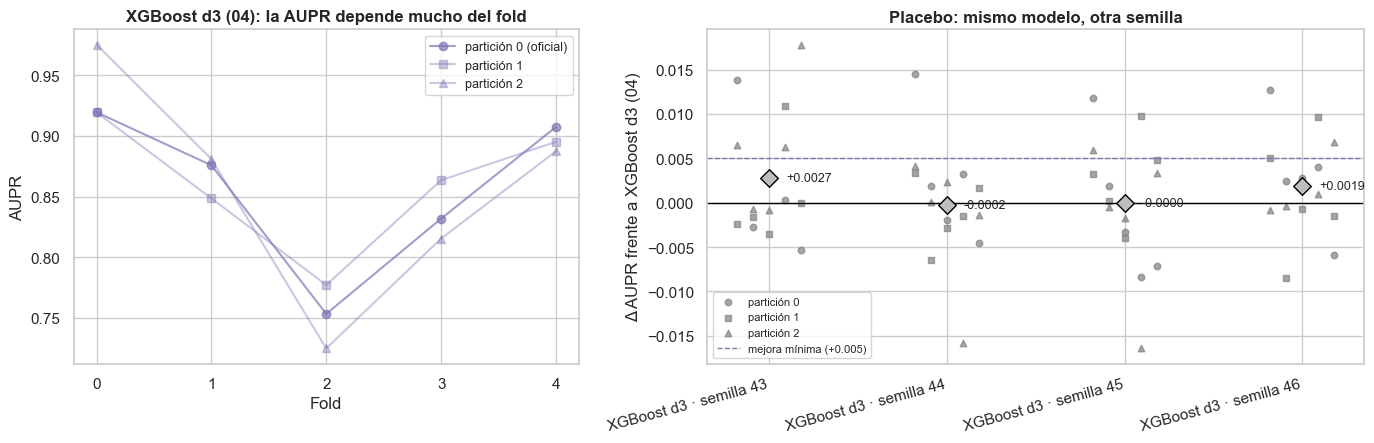

In [5]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 4.6), gridspec_kw={"width_ratios": [1, 1.3]})
a = RES[REF]["a"]
for r, mk in enumerate("os^"):
    a1.plot(range(5), a[r], marker=mk, c=FAM["referencia"], alpha=.4 + .3*(r == 0), label=f"partición {r}" + (" (oficial)" if r == 0 else ""))
a1.set(xticks=range(5), xlabel="Fold", ylabel="AUPR", title=f"{REF}: la AUPR depende mucho del fold")
a1.legend(fontsize=9)
plot_deltas(PLACEBOS, "Placebo: mismo modelo, otra semilla", ax=a2)
fig.tight_layout()
plt.show()

> **Conclusión:** la referencia da **0,858 ± 0,066** en los 15 folds y **0,858** en la partición oficial. La configuración es la del 04, que allí dio 0,865: el mismo XGBoost no da resultados idénticos en equipos distintos, y la diferencia (0,007) es del orden del ruido de semilla. Cambiar solo la semilla mueve la AUPR de un fold entre **-0,016 y +0,018**, y la media de los 15 folds hasta **0,0027**. La semilla 42 queda en la parte baja de los placebos (0,858 frente a 0,858–0,861). → **Impacto:** una mejora real tiene que superar **+0,005** de media, repetirse en al menos 11 de 15 folds y quedar por encima de 0,0027. Por debajo de eso no se distingue de cambiar la semilla.

## 2. ¿Sirve promediar semillas o ir más despacio?

**Qué miramos y por qué.** Dos cambios que no tocan la estructura del modelo:

- **Cinco semillas promediadas.** Cada semilla ve submuestras distintas de filas y columnas. Promediar sus probabilidades reduce la varianza del modelo. Se construye con los placebos de §1, que ya están ajustados en los mismos folds: es la media de las probabilidades de las semillas 42–46.
- **Más árboles con un ritmo más lento.** Un `learning_rate` de 0,02 con 1.200 árboles hace pasos más pequeños que 0,05 × 400, con un presupuesto parecido. Suele dar un ajuste algo más fino.

XGBoost d3 · 5 semillas: AUPR 15 folds = 0.8612 ± 0.0677 | oficial = 0.8604 (97 s)


XGBoost d3 · 1.200 árboles, lr 0,02: AUPR 15 folds = 0.8642 ± 0.0667 | oficial = 0.8643 (49 s)


,familia,media 15 folds,std,oficial (5 folds),Δ medio,Δ particiones 1–2,peor Δ fold,gana (de 15),segundos
"XGBoost d3 · 1.200 árboles, lr 0,02",semillas,0.8642,0.0667,0.8643,0.0059,0.0054,-0.0028,12.0,48.6778
XGBoost d3 · 5 semillas,semillas,0.8612,0.0677,0.8604,0.0029,0.0029,-0.0032,10.0,96.6417
XGBoost d3 (04),referencia,0.8583,0.0656,0.8575,0.0000,0.0000,0.0000,0.0,20.9094


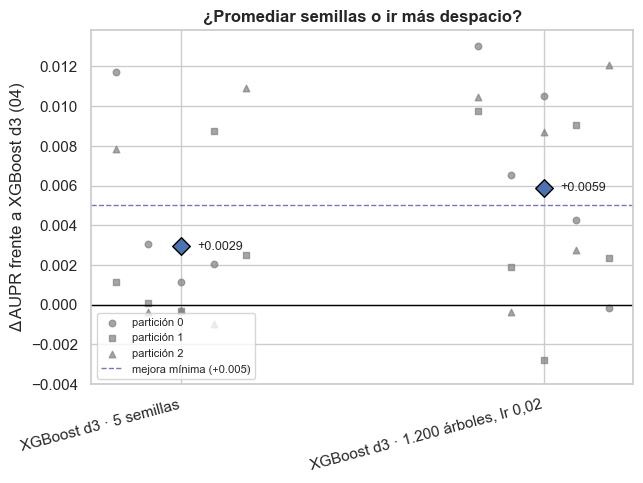

In [6]:
BOLSA, LENTO = "XGBoost d3 · 5 semillas", "XGBoost d3 · 1.200 árboles, lr 0,02"
combinar(BOLSA, [REF, *PLACEBOS], "semillas", como="media")
evaluar(LENTO, XGB(n_estimators=1200, learning_rate=.02), "semillas")
display(tabla([REF, BOLSA, LENTO]).round(4))
plot_deltas([BOLSA, LENTO], "¿Promediar semillas o ir más despacio?")
plt.show()

> **Conclusión:** promediar cinco semillas da **0,861** (Δ **+0,0029**, gana en 10 de 15 folds): reduce la varianza, pero no llega a la mejora mínima. Ir más despacio, con 1.200 árboles y ritmo 0,02, da **0,864** (Δ **+0,0059**, gana en **12 de 15** folds y el peor fold solo pierde 0,003). → **Impacto:** el XGBoost lento cumple la regla y pasa a la comparación final. Las semillas promediadas sirven como referencia de robustez en §8.

## 3. ¿Mejora ajustando los hiperparámetros?

**Qué miramos y por qué.** El 03 vio que la AUPR apenas cambia con la profundidad, el ritmo y las semillas (D-2.5). Pero solo movió unos pocos parámetros a la vez. Aquí se hace una **búsqueda bayesiana con Optuna** (TPE, 40 pruebas) de nueve parámetros a la vez, incluidos los de regularización que el 03 no tocó (`min_child_weight`, `gamma`, `reg_lambda`, `max_delta_step`).

- **Objetivo:** AUPR media en los 5 folds **de la partición oficial**. La primera prueba es la configuración de referencia, para que la búsqueda parta de ella.
- **Riesgo:** con 40 pruebas sobre los mismos 5 folds, la mejor cifra está inflada (se elige el máximo de muchos valores ruidosos). Por eso la configuración ganadora se reevalúa en las **particiones 1–2, que la búsqueda no ha visto**, y la regla de §1 le exige mejorar también ahí.
- No se reequilibran las clases (D-2.6).

In [7]:
N_PRUEBAS = 40
def objetivo(trial):
    p = dict(max_depth=trial.suggest_int("max_depth", 2, 6),
             learning_rate=trial.suggest_float("learning_rate", .01, .15, log=True),
             n_estimators=trial.suggest_int("n_estimators", 200, 1200, step=100),
             min_child_weight=trial.suggest_float("min_child_weight", .5, 20, log=True),
             subsample=trial.suggest_float("subsample", .5, 1.),
             colsample_bytree=trial.suggest_float("colsample_bytree", .3, 1.),
             gamma=trial.suggest_float("gamma", 0, 5),
             reg_lambda=trial.suggest_float("reg_lambda", .1, 30, log=True),
             max_delta_step=trial.suggest_float("max_delta_step", 0, 5))
    return np.mean([average_precision_score(ya[iv], score(fit(XGB(**p), Xa[it], ya[it]), Xa[iv])) for it, iv in cv_splits])

t0 = time.time()
estudio = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEED))
estudio.enqueue_trial(dict(max_depth=3, learning_rate=.05, n_estimators=400, min_child_weight=1, subsample=.8,
                           colsample_bytree=.7, gamma=0, reg_lambda=1, max_delta_step=0))   # = referencia
estudio.optimize(objetivo, n_trials=N_PRUEBAS)
PRUEBAS = estudio.trials_dataframe()
MEJOR = estudio.best_params
print(f"{N_PRUEBAS} pruebas en {time.time()-t0:.0f} s | referencia (prueba 0) = {PRUEBAS.value[0]:.4f} | "
      f"mejor = {estudio.best_value:.4f} (prueba {estudio.best_trial.number})")
pd.Series(MEJOR, name="mejor configuración").to_frame().T.round(4)

40 pruebas en 280 s | referencia (prueba 0) = 0.8575 | mejor = 0.8621 (prueba 12)


,max_depth,learning_rate,n_estimators,min_child_weight,subsample,colsample_bytree,gamma,reg_lambda,max_delta_step
mejor configuración,3.0,0.0975,300.0,1.56,0.5834,0.6572,1.3568,0.2435,0.7759


XGBoost ajustado (Optuna): AUPR 15 folds = 0.8553 ± 0.0674 | oficial = 0.8621 (15 s)


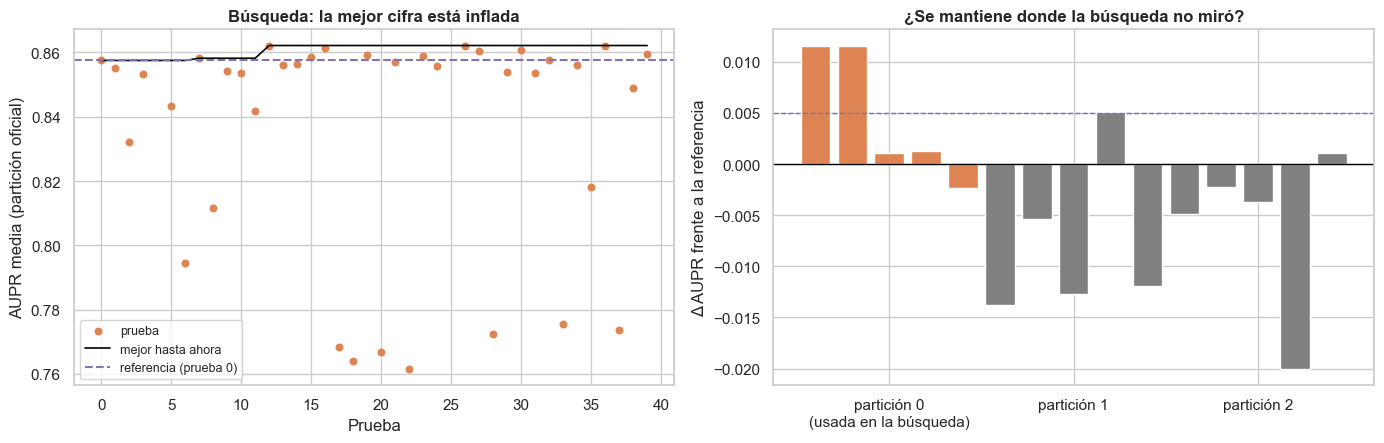

,familia,media 15 folds,std,oficial (5 folds),Δ medio,Δ particiones 1–2,peor Δ fold,gana (de 15),segundos
XGBoost d3 (04),referencia,0.8583,0.0656,0.8575,0.000,0.0000,0.0000,0.0,20.9094
XGBoost ajustado (Optuna),ajuste fino,0.8553,0.0674,0.8621,-0.003,-0.0068,-0.0201,6.0,14.8271


In [8]:
AFIN = "XGBoost ajustado (Optuna)"
evaluar(AFIN, XGB(**MEJOR), "ajuste fino")
fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 4.6))
a1.scatter(PRUEBAS.number, PRUEBAS.value, c=FAM["ajuste fino"], s=22, label="prueba")
a1.plot(PRUEBAS.number, PRUEBAS.value.cummax(), c="black", lw=1.2, label="mejor hasta ahora")
a1.axhline(PRUEBAS.value[0], c=FAM["referencia"], ls="--", label="referencia (prueba 0)")
a1.set(xlabel="Prueba", ylabel="AUPR media (partición oficial)", title="Búsqueda: la mejor cifra está inflada")
a1.set_ylim(PRUEBAS.value.quantile(.1) - .01, PRUEBAS.value.max() + .005)
a1.legend(fontsize=9)
d = delta(AFIN)
a2.bar(np.arange(15), d.ravel(), color=[FAM["ajuste fino"] if r == 0 else "grey" for r in range(3) for _ in range(5)])
a2.axhline(0, c="black", lw=1)
a2.axhline(MIN_MEJORA, c=FAM["referencia"], ls="--", lw=1)
a2.set(xticks=[2, 7, 12], xticklabels=["partición 0\n(usada en la búsqueda)", "partición 1", "partición 2"],
       ylabel="Δ AUPR frente a la referencia", title="¿Se mantiene donde la búsqueda no miró?")
fig.tight_layout()
plt.show()
tabla([REF, AFIN]).round(4)

> **Conclusión:** la búsqueda encuentra una configuración con **0,862** en la partición oficial (prueba 12, frente a 0,858 de la referencia): `learning_rate` 0,097, 300 árboles, profundidad 3, `subsample` 0,58, `gamma` 1,36. En las particiones que no ha visto, en cambio, **baja 0,0068**, y en los 15 folds queda en **0,855** (Δ **-0,0030**, gana en 6 de 15). La mejora de la búsqueda era sobreajuste a los 5 folds oficiales. → **Impacto:** confirma el 03: los hiperparámetros del XGBoost ya están en una meseta. El modelo ajustado se descarta, y no se vuelve a buscar.

## 4. ¿Y otros modelos de árboles?

**Qué miramos y por qué.** Tres modelos con otra forma de construir los árboles. Sirven como alternativa y como piezas para mezclar en §6:

- **CatBoost** (profundidad 6, 1.000 árboles, ritmo 0,05): árboles simétricos, todos los nodos de un nivel con el mismo corte. Regulariza de otra forma que XGBoost y no se probó en el 03.
- **LightGBM** con `min_child_weight` = 5, la versión que en el 03 empataba con XGBoost (D-2.6).
- **Random Forest 300**, el mejor modelo que no es boosting en el 03 (0,851). Promedia árboles profundos e independientes, así que se equivoca de forma distinta.

CatBoost d6: AUPR 15 folds = 0.8610 ± 0.0700 | oficial = 0.8597 (196 s)


LightGBM mcw 5: AUPR 15 folds = 0.8622 ± 0.0670 | oficial = 0.8624 (5 s)


Random Forest 300: AUPR 15 folds = 0.8489 ± 0.0702 | oficial = 0.8508 (110 s)


,familia,media 15 folds,std,oficial (5 folds),Δ medio,Δ particiones 1–2,peor Δ fold,gana (de 15),segundos
LightGBM mcw 5,otro modelo,0.8622,0.0670,0.8624,0.0040,0.0035,-0.0233,8.0,4.6916
CatBoost d6,otro modelo,0.8610,0.0700,0.8597,0.0027,0.0030,-0.0176,8.0,196.1996
XGBoost d3 (04),referencia,0.8583,0.0656,0.8575,0.0000,0.0000,0.0000,0.0,20.9094
Random Forest 300,otro modelo,0.8489,0.0702,0.8508,-0.0094,-0.0107,-0.0531,7.0,109.5487


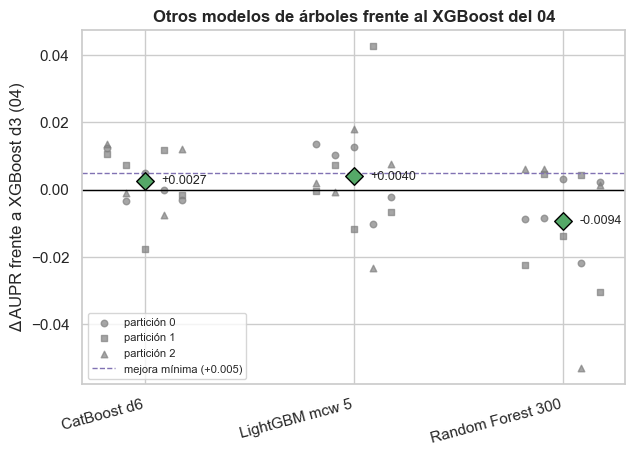

In [9]:
CAT, LGBM, RF = "CatBoost d6", "LightGBM mcw 5", "Random Forest 300"
evaluar(CAT, cb.CatBoostClassifier(iterations=1000, learning_rate=.05, depth=6, random_seed=SEED, verbose=0,
                                   thread_count=N_JOBS, allow_writing_files=False), "otro modelo")
evaluar(LGBM, lgb.LGBMClassifier(min_child_weight=5, verbose=-1, n_jobs=N_JOBS, random_state=SEED), "otro modelo")
evaluar(RF, RandomForestClassifier(300, min_samples_leaf=2, n_jobs=N_JOBS, random_state=SEED), "otro modelo")
display(tabla([REF, CAT, LGBM, RF]).round(4))
plot_deltas([CAT, LGBM, RF], "Otros modelos de árboles frente al XGBoost del 04")
plt.show()

> **Conclusión:** ninguno mejora al XGBoost de forma consistente. **LightGBM** (0,862, Δ +0,0040) y **CatBoost** (0,861, Δ +0,0027) ganan solo en 8 de 15 folds y pierden hasta 0,023 y 0,018 en alguno. **Random Forest** queda por debajo (0,849, Δ -0,0094). → **Impacto:** como modelos únicos no sustituyen a la referencia. Pero sus errores no coinciden fold a fold con los del XGBoost, que es justo lo que necesita una mezcla (§6).

## 5. ¿Ayudan variables nuevas?

**Qué miramos y por qué.** El 01 encontró que los fraudes repiten importes exactos, y el 03 que quitar `amount_freq` cuesta AUPR. Probamos tres variables más en esa línea, **sin etiquetas** y con el mismo cálculo transductivo que `amount_freq` (construcción + producción, D-1.4):

- `frec_fila`: cuántas veces aparece la transacción completa, idéntica en sus 21 variables. Generaliza `amount_freq` a la fila entera.
- `importe_entero`: el importe no tiene céntimos (1,00, 50,00…).
- `importe_99`: el importe acaba en ,99.

Primero se describe cuánto fraude hay en cada grupo (solo con train). Después se mide si el XGBoost de referencia mejora con las tres variables.

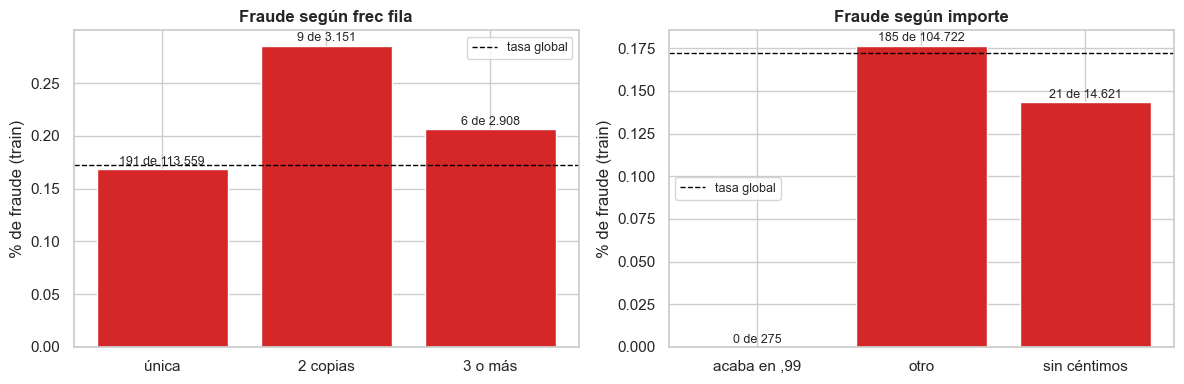

XGBoost d3 + 3 variables: AUPR 15 folds = 0.8603 ± 0.0661 | oficial = 0.8610 (17 s)


,familia,media 15 folds,std,oficial (5 folds),Δ medio,Δ particiones 1–2,peor Δ fold,gana (de 15),segundos
XGBoost d3 + 3 variables,variables,0.8603,0.0661,0.8610,0.002,0.0013,-0.0026,9.0,16.7373
XGBoost d3 (04),referencia,0.8583,0.0656,0.8575,0.000,0.0000,0.0000,0.0,20.9094


In [10]:
NUEVAS = ["frec_fila", "importe_entero", "importe_99"]
clave = pd.util.hash_pandas_object(df[FEAT_RAW], index=False)
centimos = np.round(df["Amount"] * 100).astype(np.int64) % 100
extra = pd.DataFrame({"split": df["split"], "row_id": df["row_id"], "frec_fila": clave.map(clave.value_counts()).to_numpy(),
                      "importe_entero": (centimos == 0).astype(int), "importe_99": (centimos == 99).astype(int)})

def con_nuevas(d):
    e = d[["split", "row_id"]].merge(extra, on=["split", "row_id"], how="left", validate="one_to_one", sort=False)
    assert len(e) == len(d) and e[NUEVAS].notna().all().all()
    return np.c_[d[FEATURES].to_numpy(float), e[NUEVAS].to_numpy(float)]

X_tr_n = con_nuevas(tr)
d_tr = pd.DataFrame(X_tr_n[:, -3:], columns=NUEVAS).assign(Class=ya)
d_tr["frec_fila"] = pd.cut(d_tr["frec_fila"], [0, 1, 2, np.inf], labels=["única", "2 copias", "3 o más"])
d_tr["importe"] = np.select([d_tr.importe_entero == 1, d_tr.importe_99 == 1], ["sin céntimos", "acaba en ,99"], "otro")
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, col in zip(axes, ["frec_fila", "importe"]):
    t = d_tr.groupby(col, observed=True)["Class"].agg(["mean", "size", "sum"])
    ax.bar(t.index.astype(str), 100 * t["mean"], color=C[1])
    ax.axhline(100 * ya.mean(), c="black", ls="--", lw=1, label="tasa global")
    for i, (m, n, f) in enumerate(t.to_numpy()):
        ax.annotate(f"{int(f)} de {int(n):,}".replace(",", "."), (i, 100 * m), xytext=(0, 3), textcoords="offset points", ha="center", fontsize=9)
    ax.set(ylabel="% de fraude (train)", title=f"Fraude según {col.replace('_', ' ')}")
    ax.legend(fontsize=9)
fig.tight_layout()
plt.show()

NUEV = "XGBoost d3 + 3 variables"
evaluar(NUEV, XGB_FINAL, "variables", X=X_tr_n)
tabla([REF, NUEV]).round(4)

> **Conclusión:** las nuevas variables no separan el fraude: los importes acabados en ,99 no tienen **ningún** fraude (0 de 275), los importes sin céntimos tienen menos fraude que el resto (0,14 % frente a 0,18 %) y las filas repetidas tienen algo más, pero con solo 15 fraudes (0,29 % y 0,21 % frente a 0,17 %). El XGBoost con las tres variables da **0,860** (Δ +0,0020, gana en 9 de 15). → **Impacto:** se descartan. La información de importes repetidos ya la recoge `amount_freq`.

## 6. ¿Ayuda mezclar modelos?

**Qué miramos y por qué.** Si dos modelos se equivocan en filas distintas, su media puede ordenar mejor que cada uno. Se mezclan **con pesos iguales y por rangos**: cada score se convierte en su posición dentro del fold (0–1) y se promedian las posiciones. Así no importa que cada modelo use otra escala de probabilidad, y no se ajusta ningún peso, que con 206 fraudes sería otra fuente de sobreajuste. Primero se mide cuánto se parecen los rankings OOF (Spearman sobre las filas de validación de la partición oficial).

Mezcla XGB + RF: AUPR 15 folds = 0.8618 ± 0.0683 | oficial = 0.8645 (130 s)


Mezcla XGB + CatBoost: AUPR 15 folds = 0.8635 ± 0.0679 | oficial = 0.8631 (217 s)


Mezcla XGB + CatBoost + RF: AUPR 15 folds = 0.8654 ± 0.0689 | oficial = 0.8677 (327 s)


Mezcla XGB + CatBoost + LightGBM + RF: AUPR 15 folds = 0.8663 ± 0.0689 | oficial = 0.8680 (331 s)


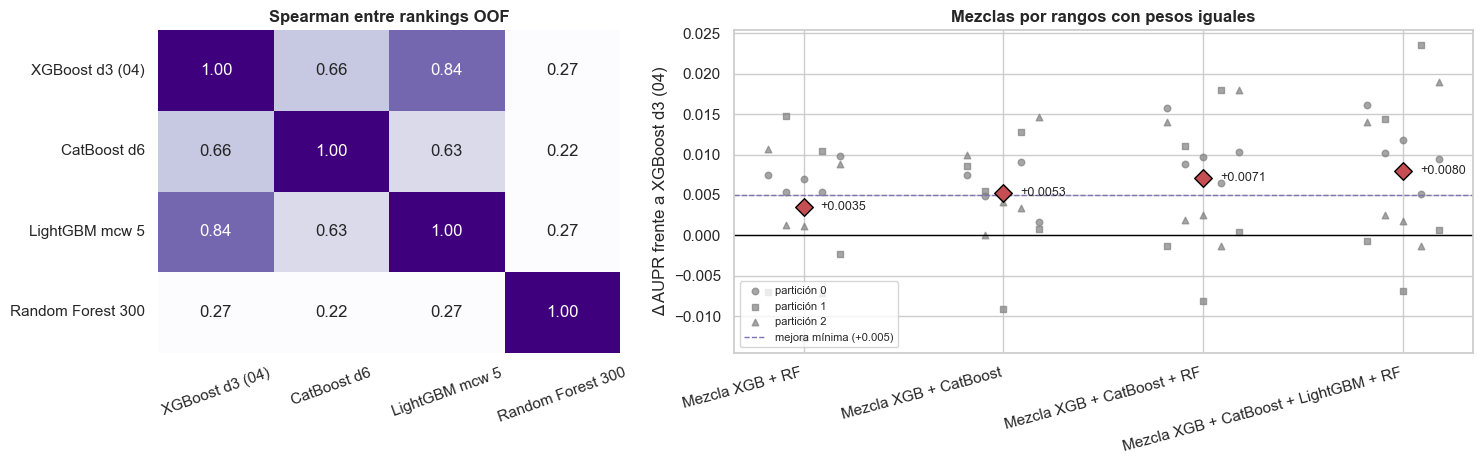

,familia,media 15 folds,std,oficial (5 folds),Δ medio,Δ particiones 1–2,peor Δ fold,gana (de 15),segundos
Mezcla XGB + CatBoost + LightGBM + RF,mezcla,0.8663,0.0689,0.8680,0.0080,0.0067,-0.0069,12.0,331.3492
Mezcla XGB + CatBoost + RF,mezcla,0.8654,0.0689,0.8677,0.0071,0.0055,-0.0082,12.0,326.6577
Mezcla XGB + CatBoost,mezcla,0.8635,0.0679,0.8631,0.0053,0.0051,-0.0092,14.0,217.1090
Mezcla XGB + RF,mezcla,0.8618,0.0683,0.8645,0.0035,0.0018,-0.0127,11.0,130.4581
XGBoost d3 (04),referencia,0.8583,0.0656,0.8575,0.0000,0.0000,0.0000,0.0,20.9094


In [11]:
BASE = [REF, CAT, LGBM, RF]
rho = pd.DataFrame(stats.spearmanr(np.column_stack([OOF[n][0] for n in BASE])).statistic, index=BASE, columns=BASE)
MEZCLAS = {"Mezcla XGB + RF": [REF, RF], "Mezcla XGB + CatBoost": [REF, CAT],
           "Mezcla XGB + CatBoost + RF": [REF, CAT, RF], "Mezcla XGB + CatBoost + LightGBM + RF": [REF, CAT, LGBM, RF]}
for n, comp in MEZCLAS.items():
    combinar(n, comp, "mezcla")
fig, (a1, a2) = plt.subplots(1, 2, figsize=(15, 4.8), gridspec_kw={"width_ratios": [1, 1.6]})
sns.heatmap(rho, annot=True, fmt=".2f", cmap="Purples", vmin=.5, vmax=1, ax=a1, cbar=False)
a1.set_title("Spearman entre rankings OOF")
a1.tick_params(axis="x", rotation=20)
plot_deltas(list(MEZCLAS), "Mezclas por rangos con pesos iguales", ax=a2)
fig.tight_layout()
plt.show()
tabla([REF, *MEZCLAS]).round(4)

> **Conclusión:** los rankings se parecen poco: Spearman 0,84 entre XGBoost y LightGBM, 0,67 con CatBoost y solo 0,27 con Random Forest. Mezclar mejora siempre, y más cuanto más distintos son los modelos: XGB + RF **0,862** (Δ +0,0035), XGB + CatBoost **0,864** (Δ +0,0053, gana en **14 de 15**), XGB + CatBoost + RF **0,865** (Δ +0,0071) y los cuatro juntos **0,866** (Δ **+0,0080**, gana en 12 de 15, peor fold -0,007). El Random Forest, peor que la referencia por sí solo, aporta dentro de la mezcla. → **Impacto:** las mezclas con CatBoost son las mejores candidatas. No se ajustan pesos, así que la mejora no viene de ajustar la mezcla a estos folds.

---
# PARTE II · COMPARACIÓN Y ENTREGA

Se comparan todos los candidatos con la regla de §1 y la elección se cierra antes de puntuar el test. Después se confirma en test, se revisan las copias exactas de fraudes conocidos y se reajusta el elegido con toda construcción para generar el entregable.

## 7. ¿Qué gana en CV?

**Qué miramos y por qué.** Todos los candidatos juntos, en los mismos 15 folds. La columna `Δ particiones 1–2` es la que importa para el modelo de Optuna. La franja gris marca el ruido de semilla medido en §1.

,familia,media 15 folds,std,oficial (5 folds),Δ medio,Δ particiones 1–2,peor Δ fold,gana (de 15),segundos
Mezcla XGB + CatBoost + LightGBM + RF,mezcla,0.8663,0.0689,0.8680,0.0080,0.0067,-0.0069,12.0,331.3492
Mezcla XGB + CatBoost + RF,mezcla,0.8654,0.0689,0.8677,0.0071,0.0055,-0.0082,12.0,326.6577
"XGBoost d3 · 1.200 árboles, lr 0,02",semillas,0.8642,0.0667,0.8643,0.0059,0.0054,-0.0028,12.0,48.6778
Mezcla XGB + CatBoost,mezcla,0.8635,0.0679,0.8631,0.0053,0.0051,-0.0092,14.0,217.1090
LightGBM mcw 5,otro modelo,0.8622,0.0670,0.8624,0.0040,0.0035,-0.0233,8.0,4.6916
Mezcla XGB + RF,mezcla,0.8618,0.0683,0.8645,0.0035,0.0018,-0.0127,11.0,130.4581
XGBoost d3 · 5 semillas,semillas,0.8612,0.0677,0.8604,0.0029,0.0029,-0.0032,10.0,96.6417
CatBoost d6,otro modelo,0.8610,0.0700,0.8597,0.0027,0.0030,-0.0176,8.0,196.1996
XGBoost d3 + 3 variables,variables,0.8603,0.0661,0.8610,0.0020,0.0013,-0.0026,9.0,16.7373
XGBoost d3 (04),referencia,0.8583,0.0656,0.8575,0.0000,0.0000,0.0000,0.0,20.9094


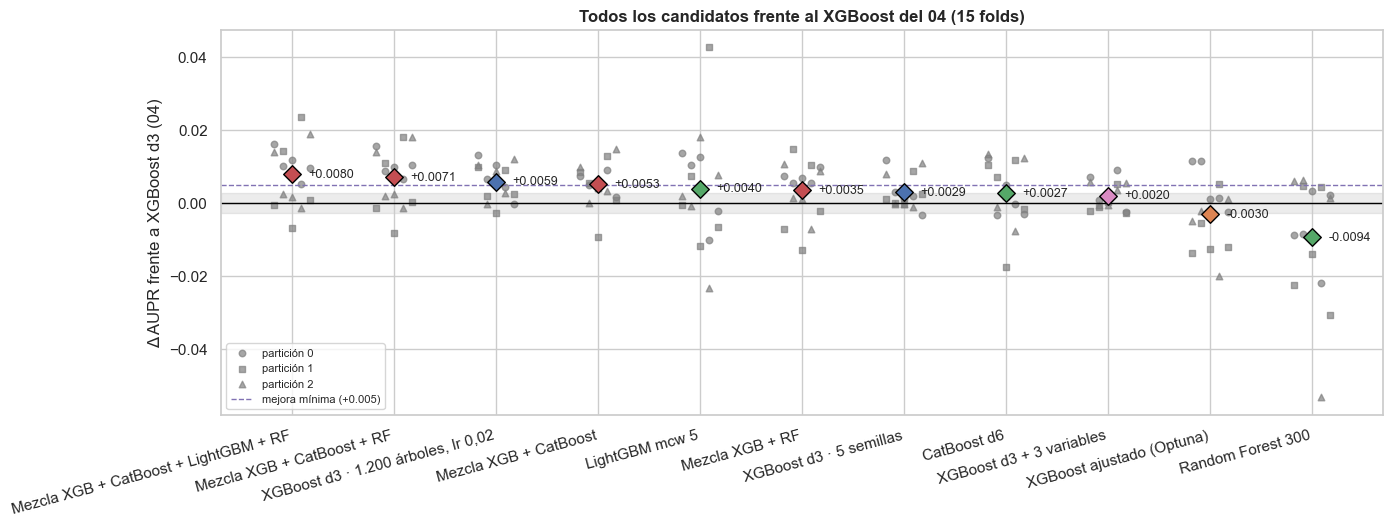

In [12]:
CANDIDATOS = [BOLSA, LENTO, AFIN, CAT, LGBM, RF, NUEV, *MEZCLAS]
CV = tabla([REF, *CANDIDATOS])
display(CV.round(4))
orden = CV.index.drop(REF).tolist()
ax = plot_deltas(orden, "Todos los candidatos frente al XGBoost del 04 (15 folds)")
ax.axhspan(-RUIDO, RUIDO, color="grey", alpha=.15, zorder=0)
ax.figure.set_size_inches(15, 5)
plt.show()

> **Conclusión:** cuatro candidatos superan la mejora mínima con al menos 11 victorias de 15: la mezcla de cuatro modelos (**0,866**, Δ +0,0080), la de tres (0,865, Δ +0,0071), el XGBoost lento (0,864, Δ +0,0059) y XGB + CatBoost (0,864, Δ +0,0053). Todos mejoran también en las particiones 1–2. Optuna y Random Forest quedan por debajo de la referencia. → **Impacto:** las ganancias son pequeñas (menos de una centésima), pero consistentes fold a fold y por encima del ruido de semilla.

## 8. ¿Qué modelo elegimos antes del test?

**Qué miramos y por qué.** Se aplica la regla de §1 tal cual: Δ medio ≥ +0,005, ≥ 11 victorias de 15 y Δ medio por encima del ruido de semilla; al modelo de Optuna se le exige además Δ ≥ +0,005 en las particiones 1–2. La elección se guarda en `05_seleccion_modelo.json` **antes** de calcular ningún score de test.

**Comprobación de robustez.** En §1, la semilla 42 de la referencia queda en la parte baja de los placebos, así que una parte de cada Δ podría venir de una referencia "con mala suerte". Por eso se mide también a los elegibles frente al **XGBoost con 5 semillas** (§2), que no depende de una semilla concreta. Esta comprobación no cambia la regla, pero si el elegido no mejorara también ahí, la elección no sería fiable.

In [13]:
def cumple(n):
    d = delta(n)
    c = {"Δ medio ≥ 0,005": d.mean() >= MIN_MEJORA, "gana ≥ 11 de 15": (d > 0).sum() >= MIN_VICTORIAS,
         "supera el ruido de semilla": d.mean() > RUIDO}
    if n == AFIN:
        c["Δ particiones 1–2 ≥ 0,005"] = d[1:].mean() >= MIN_MEJORA
    return c

REGLA = pd.DataFrame({n: cumple(n) for n in CANDIDATOS}).T
REGLA["cumple"] = REGLA.fillna(True).all(axis=1)
ELEGIBLES = REGLA.index[REGLA["cumple"]].tolist()
ELEGIDO = max(ELEGIBLES, key=lambda n: delta(n).mean()) if ELEGIBLES else REF
ELECCION = {"modelo": ELEGIDO, "elegibles": ELEGIBLES,
            "criterio": "Δ medio ≥ 0,005 en 15 folds, ≥ 11 victorias, Δ medio > ruido de semilla; Optuna: Δ ≥ 0,005 en particiones 1–2",
            "ruido_semilla": RUIDO, "cv_media_15": float(RES[ELEGIDO]["a"].mean()), "cv_std_15": float(RES[ELEGIDO]["a"].std()),
            "cv_oficial": float(RES[ELEGIDO]["a"][0].mean()), "delta_medio": float(delta(ELEGIDO).mean()),
            "optuna_mejor": MEJOR, "semilla": SEED, "versiones": VERSIONES}
(OUTPUT_DIR / "05_seleccion_modelo.json").write_text(json.dumps(ELECCION, ensure_ascii=False, indent=2, default=str), encoding="utf-8")
print(f"Modelo elegido antes del test: {ELEGIDO}")
REGLA.join(CV[["Δ medio", "gana (de 15)", "Δ particiones 1–2"]].round(4))

Modelo elegido antes del test: Mezcla XGB + CatBoost + LightGBM + RF


,"Δ medio ≥ 0,005",gana ≥ 11 de 15,supera el ruido de semilla,"Δ particiones 1–2 ≥ 0,005",cumple,Δ medio,gana (de 15),Δ particiones 1–2
XGBoost d3 · 5 semillas,False,False,True,NaN,False,0.0029,10.0,0.0029
"XGBoost d3 · 1.200 árboles, lr 0,02",True,True,True,NaN,True,0.0059,12.0,0.0054
XGBoost ajustado (Optuna),False,False,False,False,False,-0.0030,6.0,-0.0068
CatBoost d6,False,False,False,NaN,False,0.0027,8.0,0.0030
LightGBM mcw 5,False,False,True,NaN,False,0.0040,8.0,0.0035
Random Forest 300,False,False,False,NaN,False,-0.0094,7.0,-0.0107
XGBoost d3 + 3 variables,False,False,False,NaN,False,0.0020,9.0,0.0013
Mezcla XGB + RF,False,True,True,NaN,False,0.0035,11.0,0.0018
Mezcla XGB + CatBoost,True,True,True,NaN,True,0.0053,14.0,0.0051
Mezcla XGB + CatBoost + RF,True,True,True,NaN,True,0.0071,12.0,0.0055


In [14]:
SEMILLAS_MEDIA = np.mean([RES[n]["a"] for n in [REF, *PLACEBOS]], axis=0)   # AUPR media de las 5 semillas, fold a fold
ROBUSTEZ = pd.DataFrame({n: {"Δ frente a 5 semillas": (RES[n]["a"] - RES[BOLSA]["a"]).mean(),
                             "gana a 5 semillas (de 15)": int((RES[n]["a"] > RES[BOLSA]["a"]).sum()),
                             "Δ frente a la semilla media": (RES[n]["a"] - SEMILLAS_MEDIA).mean(),
                             "gana a la semilla media (de 15)": int((RES[n]["a"] > SEMILLAS_MEDIA).sum())}
                         for n in ELEGIBLES or [REF]}).T
ELECCION["robustez"] = ROBUSTEZ.loc[ELEGIDO].to_dict() if ELEGIDO in ROBUSTEZ.index else {}
(OUTPUT_DIR / "05_seleccion_modelo.json").write_text(json.dumps(ELECCION, ensure_ascii=False, indent=2, default=str), encoding="utf-8")
ROBUSTEZ.astype(float).round(4)

,Δ frente a 5 semillas,gana a 5 semillas (de 15),Δ frente a la semilla media,gana a la semilla media (de 15)
"XGBoost d3 · 1.200 árboles, lr 0,02",0.0029,12.0,0.0050,13.0
Mezcla XGB + CatBoost,0.0023,12.0,0.0044,12.0
Mezcla XGB + CatBoost + RF,0.0041,11.0,0.0062,12.0
Mezcla XGB + CatBoost + LightGBM + RF,0.0050,11.0,0.0071,12.0


> **Conclusión:** la regla deja **cuatro elegibles** y se elige el de mayor Δ medio: la **mezcla por rangos de XGBoost, CatBoost, LightGBM y Random Forest**, con **0,866 ± 0,069** en los 15 folds (0,868 en la partición oficial) y Δ **+0,0080**. Supera la comprobación de robustez: frente al XGBoost con 5 semillas mejora **+0,0050** y gana en 11 de 15 folds; frente a la semilla media, **+0,0071** y 12 de 15. → **Impacto:** la elección queda cerrada y registrada antes del test. El coste es entrenar cuatro modelos en lugar de uno (menos de un minuto con toda construcción).

## 9. ¿Se confirma en test?

**Qué miramos y por qué.** La elección ya está cerrada. Se ajustan todos los candidatos con todo train y se puntúa el test (89 fraudes). Las mezclas se calculan con rangos dentro del test, igual que dentro de cada fold. El bootstrap pareado (1.000 réplicas, estratificado) da el intervalo de la diferencia de cada candidato con la referencia en las mismas filas. El test ya se examinó en 02–04: es una confirmación interna, **no cambia la elección**.

In [15]:
MATRICES = {"base": (Xa, X_test.to_numpy(float), X_prod.to_numpy(float), df_const[FEATURES].to_numpy(float)),
            "nuevas": (X_tr_n, con_nuevas(te), con_nuevas(df_prod), con_nuevas(df_const))}
ESPEC = {REF: ("modelo", XGB_FINAL, "base"), LENTO: ("modelo", XGB(n_estimators=1200, learning_rate=.02), "base"),
         AFIN: ("modelo", XGB(**MEJOR), "base"),
         CAT: ("modelo", cb.CatBoostClassifier(iterations=1000, learning_rate=.05, depth=6, random_seed=SEED, verbose=0,
                                               thread_count=N_JOBS, allow_writing_files=False), "base"),
         LGBM: ("modelo", lgb.LGBMClassifier(min_child_weight=5, verbose=-1, n_jobs=N_JOBS, random_state=SEED), "base"),
         RF: ("modelo", RandomForestClassifier(300, min_samples_leaf=2, n_jobs=N_JOBS, random_state=SEED), "base"),
         NUEV: ("modelo", XGB_FINAL, "nuevas"),
         **{n: ("modelo", XGB(random_state=s), "base") for n, s in zip(PLACEBOS, (43, 44, 45, 46))},
         BOLSA: ("media", [REF, *PLACEBOS]), **{n: ("rango", comp) for n, comp in MEZCLAS.items()}}
_HECHOS = {}

def predecir(nombre, con="train"):
    """(scores de test, scores de producción) ajustando con todo train; con='construccion', (None, producción)."""
    if (nombre, con) in _HECHOS:
        return _HECHOS[nombre, con]
    e = ESPEC[nombre]
    if e[0] == "modelo":
        Xtr, Xte, Xpr, Xco = MATRICES[e[2]]
        m = fit(e[1], Xtr, ya) if con == "train" else fit(e[1], Xco, y_cons)
        out = (score(m, Xte) if con == "train" else None, score(m, Xpr))
    else:
        partes = [predecir(c, con) for c in e[1]]
        comb = (lambda ss: np.mean(ss, axis=0)) if e[0] == "media" else (lambda ss: np.mean([rango(s) for s in ss], axis=0))
        out = (comb([p[0] for p in partes]) if con == "train" else None, comb([p[1] for p in partes]))
    _HECHOS[nombre, con] = out
    return out

NOMBRES_TEST = [REF, *CANDIDATOS]
SC_TEST = {n: predecir(n)[0] for n in NOMBRES_TEST}
with contextlib.redirect_stdout(io.StringIO()):
    TEST = pd.DataFrame([report(n, SC_TEST[n]) for n in NOMBRES_TEST]).set_index("modelo")
rng = np.random.default_rng(SEED)
i0, i1 = np.flatnonzero(y_te == 0), np.flatnonzero(y_te == 1)
boot = np.empty((1000, len(NOMBRES_TEST)))
for b in range(len(boot)):
    ib = np.r_[rng.choice(i0, len(i0)), rng.choice(i1, len(i1))]
    boot[b] = [average_precision_score(y_te[ib], SC_TEST[n][ib]) for n in NOMBRES_TEST]
BOOT = pd.DataFrame(boot, columns=NOMBRES_TEST)
TEST.insert(0, "CV 15 folds", [RES[n]["a"].mean() for n in TEST.index])
TEST["Δ test frente a la referencia"] = TEST["aupr"] - TEST.loc[REF, "aupr"]
TEST["IC Δ 2.5 %"] = [(BOOT[n] - BOOT[REF]).quantile(.025) for n in TEST.index]
TEST["IC Δ 97.5 %"] = [(BOOT[n] - BOOT[REF]).quantile(.975) for n in TEST.index]
TEST = TEST.sort_values("CV 15 folds", ascending=False)
print(f"Elección mantenida: {ELEGIDO}")
TEST.round(4)

Elección mantenida: Mezcla XGB + CatBoost + LightGBM + RF


,CV 15 folds,aupr,roc_auc,aupr_sin_dup,Δ test frente a la referencia,IC Δ 2.5 %,IC Δ 97.5 %
modelo,,,,,,,
Mezcla XGB + CatBoost + LightGBM + RF,0.8663,0.8217,0.9743,0.8091,0.0049,-0.0108,0.0211
Mezcla XGB + CatBoost + RF,0.8654,0.8161,0.9766,0.8020,-0.0007,-0.0301,0.0237
"XGBoost d3 · 1.200 árboles, lr 0,02",0.8642,0.8160,0.9774,0.8023,-0.0008,-0.0151,0.0127
Mezcla XGB + CatBoost,0.8635,0.8183,0.9764,0.8061,0.0015,-0.0119,0.0137
LightGBM mcw 5,0.8622,0.8142,0.9648,0.8001,-0.0026,-0.0222,0.0212
Mezcla XGB + RF,0.8618,0.8114,0.9734,0.7973,-0.0054,-0.0322,0.0128
XGBoost d3 · 5 semillas,0.8612,0.8160,0.9766,0.8029,-0.0008,-0.0110,0.0063
CatBoost d6,0.8610,0.8125,0.9732,0.7996,-0.0043,-0.0254,0.0114
XGBoost d3 + 3 variables,0.8603,0.8120,0.9736,0.7986,-0.0048,-0.0168,0.0049


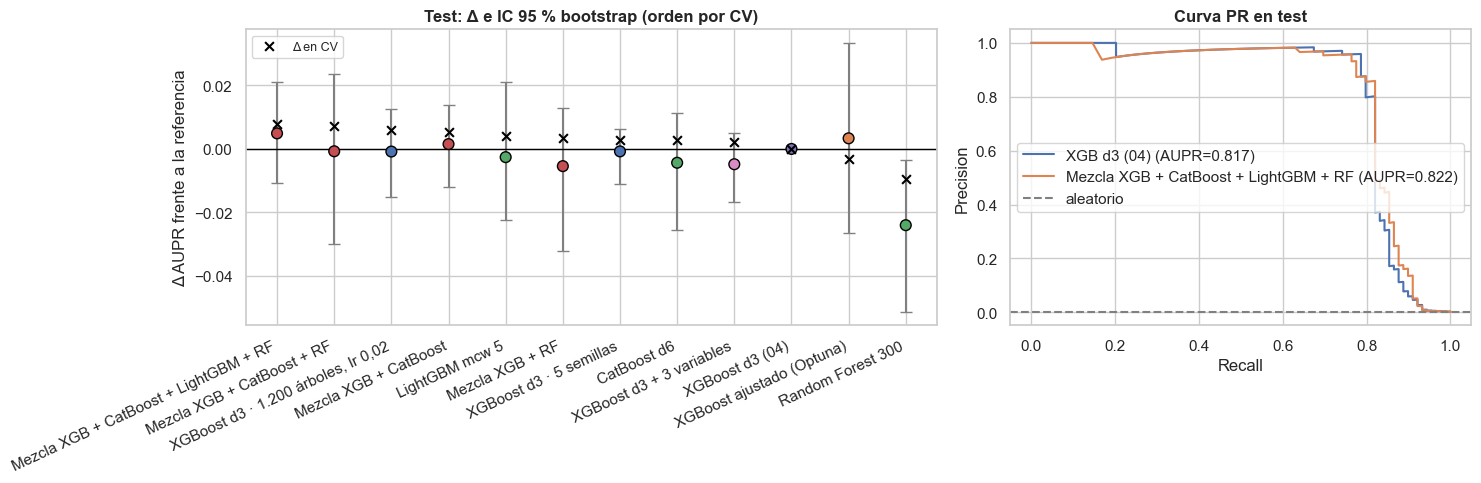

In [16]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={"width_ratios": [1.5, 1]})
x = np.arange(len(TEST))
cols = [FAM[FAMILIA[n]] for n in TEST.index]
a1.errorbar(x, TEST["Δ test frente a la referencia"], yerr=[TEST["Δ test frente a la referencia"] - TEST["IC Δ 2.5 %"],
            TEST["IC Δ 97.5 %"] - TEST["Δ test frente a la referencia"]], fmt="none", ecolor="grey", capsize=4)
a1.scatter(x, TEST["Δ test frente a la referencia"], c=cols, s=60, zorder=3, edgecolor="black")
a1.scatter(x, TEST["CV 15 folds"] - RES[REF]["a"].mean(), marker="x", c="black", s=40, zorder=4, label="Δ en CV")
a1.axhline(0, c="black", lw=1)
a1.set_xticks(x, TEST.index, rotation=25, ha="right")
a1.set(ylabel="Δ AUPR frente a la referencia", title="Test: Δ e IC 95 % bootstrap (orden por CV)")
a1.legend(fontsize=9)
plot_pr(y_te, {n.replace("XGBoost", "XGB"): SC_TEST[n] for n in dict.fromkeys([REF, ELEGIDO, TEST.index[0]])}, ax=a2)
a2.set_title("Curva PR en test")
fig.tight_layout()
plt.show()

> **Conclusión:** la mezcla elegida obtiene **0,822** en test, la cifra más alta de todos los candidatos, frente a **0,817** de la referencia (Δ **+0,0049**; IC 95 % del Δ **-0,011 a +0,021**), y **0,809** sin duplicados frente a 0,804. El intervalo incluye el 0: con 89 fraudes, el test no puede confirmar una mejora de esta escala, pero va en la misma dirección que la CV. El test también muestra su ruido: el modelo de Optuna, peor en CV, da 0,820. Solo Random Forest queda claramente por debajo (Δ -0,024, IC -0,051 a -0,003). → **Impacto:** se mantiene la elección. Como en 02–04, el test queda unas centésimas por debajo de la CV.

## 10. ¿Qué pasa con las copias exactas de fraudes?

**Qué miramos y por qué.** Hay transacciones de producción idénticas, en sus 21 variables, a alguna de construcción (01 §3, D-1.1). Si una copia exacta de un fraude etiquetado no saliera arriba del ranking, convendría una regla explícita: es el vecino más cercano a distancia 0 y usa solo etiquetas de construcción. Primero se comprueba en test, con las copias de fraudes de train, y después se cuentan en producción.

In [17]:
clave_d = pd.DataFrame({"split": df["split"], "row_id": df["row_id"], "clave": clave.to_numpy(), "Class": df["Class"]})
claves_de = lambda d: d[["split", "row_id"]].merge(clave_d, on=["split", "row_id"], validate="one_to_one", sort=False)["clave"].to_numpy()
fraude_train = set(claves_de(tr)[ya == 1])
fraude_cons = set(claves_de(df_const)[y_cons == 1])
en_te = np.isin(claves_de(te), list(fraude_train))
pct_te = 100 * rango(SC_TEST[ELEGIDO])
COPIAS = pd.DataFrame({"filas copia de un fraude": [int(en_te.sum())], "de ellas fraude": [int(y_te[en_te].sum())],
                       "percentil mínimo del score": [pct_te[en_te].min() if en_te.any() else np.nan]}, index=["test (copias de fraudes de train)"])
en_pr = np.isin(claves_de(df_prod), list(fraude_cons))
COPIAS.loc["producción (copias de fraudes de construcción)", "filas copia de un fraude"] = int(en_pr.sum())
COPIAS

,filas copia de un fraude,de ellas fraude,percentil mínimo del score
test (copias de fraudes de train),5.0,5.0,99.949284
producción (copias de fraudes de construcción),6.0,NaN,NaN


> **Conclusión:** en test hay **5 filas idénticas a fraudes de train** y las 5 son fraude: el modelo ya las sitúa en el **0,05 % superior** del ranking. En producción hay **6 copias exactas de fraudes de construcción**, y el entregable final las coloca todas en el **0,03 % superior** (§11). → **Impacto:** no hace falta ninguna regla explícita: el modelo ya pone arriba las copias de fraudes conocidos.

## 11. Reentrenar y exportar producción

**Qué miramos y por qué.** Se reajusta **el modelo elegido en §8** con toda construcción (170.884 transacciones, 295 fraudes) y se puntúa producción. Si es una mezcla, cada componente se reajusta y se promedian los rangos dentro de producción. Antes se comprueba que el XGBoost de referencia, reajustado aquí, **reproduce el entregable del 04**.

- Si el elegido es la referencia, `scores_produccion.csv` no cambia.
- Si es otro, el entregable del 04 se guarda antes como `04_scores_produccion_xgb.csv` (respaldo) y `scores_produccion.csv` pasa a ser el nuevo. Mismo formato: una columna `score`, 113.923 filas, orden de producción (D-3.1).

In [18]:
ENTREGA, RESPALDO = OUTPUT_DIR / "scores_produccion.csv", OUTPUT_DIR / "04_scores_produccion_xgb.csv"
previo = pd.read_csv(RESPALDO if RESPALDO.exists() else ENTREGA)["score"].to_numpy()   # entregable del 04
_, S_REF_FINAL = predecir(REF, "construccion")
REPRO = {"Spearman referencia 05 frente al entregable del 04": float(stats.spearmanr(S_REF_FINAL, previo).statistic),
         "máxima diferencia absoluta": float(np.abs(S_REF_FINAL - previo).max())}
if ELEGIDO == REF:
    SCORE_FINAL = previo if not RESPALDO.exists() else S_REF_FINAL
    if RESPALDO.exists():
        save_submission(SCORE_FINAL)
else:
    if not RESPALDO.exists():
        shutil.copyfile(ENTREGA, RESPALDO)
    _, SCORE_FINAL = predecir(ELEGIDO, "construccion")
    save_submission(SCORE_FINAL)
sub = pd.read_csv(ENTREGA)
assert sub.shape == (113_923, 1) and list(sub.columns) == ["score"] and np.isfinite(sub.score).all()
assert np.allclose(sub.score, SCORE_FINAL)
top1 = lambda s: set(np.argsort(-np.asarray(s))[:len(s)//100])
ESTABILIDAD = {**REPRO, "Spearman entregable final frente al del 04": float(stats.spearmanr(SCORE_FINAL, previo).statistic),
               "top 1 % compartido con el del 04 (%)": 100*len(top1(SCORE_FINAL) & top1(previo))/(len(previo)//100),
               "copias de fraudes en producción: percentil mínimo": float((100*rango(SCORE_FINAL))[en_pr].min()) if en_pr.any() else np.nan}

FOLDS = pd.DataFrame({n: RES[n]["a"].ravel() for n in [REF, *PLACEBOS, *CANDIDATOS]},
                     index=[f"partición {r} · fold {k}" for r in range(REPS) for k in range(5)])
CV.to_csv(OUTPUT_DIR / "05_metricas_cv.csv", index_label="modelo")
FOLDS.to_csv(OUTPUT_DIR / "05_aupr_por_fold.csv", index_label="fold")
TEST.to_csv(OUTPUT_DIR / "05_metricas_test.csv", index_label="modelo")
PRUEBAS.drop(columns=["datetime_start", "datetime_complete"]).to_csv(OUTPUT_DIR / "05_optuna.csv", index=False)
ELECCION.update({"test_aupr_confirmacion": float(TEST.loc[ELEGIDO, "aupr"]), "filas_reentrenamiento": len(y_cons),
                 "fraudes_reentrenamiento": int(y_cons.sum()), "estabilidad": ESTABILIDAD,
                 "sha256_dataset": hashlib.sha256(PREP_CSV.read_bytes()).hexdigest()})
(OUTPUT_DIR / "05_seleccion_modelo.json").write_text(json.dumps(ELECCION, ensure_ascii=False, indent=2, default=str), encoding="utf-8")
print(f"Entregable: {ELEGIDO}; reajuste con {len(y_cons)} transacciones, {y_cons.sum()} fraudes")
pd.Series({"filas de producción": len(sub), **ESTABILIDAD}, name="valor").round(4).to_frame()

Entregable: Mezcla XGB + CatBoost + LightGBM + RF; reajuste con 170884 transacciones, 295 fraudes


,valor
filas de producción,113923.0000
Spearman referencia 05 frente al entregable del 04,0.9520
máxima diferencia absoluta,0.1504
Spearman entregable final frente al del 04,0.9252
top 1 % compartido con el del 04 (%),63.9157
copias de fraudes en producción: percentil mínimo,99.9772


> **Conclusión:** la mezcla se reajusta con **170.884 transacciones y 295 fraudes** y genera **113.923 scores** en el orden de producción, con una columna `score` (rangos medios entre 0 y 1). El XGBoost de referencia reajustado aquí tiene Spearman **0,952** con el entregable del 04: es la misma configuración en otro equipo, la variación de implementación de §1. El nuevo entregable tiene Spearman **0,925** con el del 04 y comparte el **63,9 %** de su 1 % más sospechoso. → **Impacto:** `scores_produccion.csv` pasa a ser la mezcla. El del 04 queda como respaldo en `04_scores_produccion_xgb.csv`.

## 12. Conclusiones

1. **El ruido manda a esta escala.** Cambiar la semilla del XGBoost mueve la AUPR de un fold hasta ±0,018, y el mismo modelo cambia 0,007 de un equipo a otro. Por eso se usan 15 folds, un placebo de semillas y una regla fijada de antemano: Δ ≥ +0,005, ≥ 11 victorias de 15 y por encima del ruido de semilla.
2. **Ajustar hiperparámetros no mejora.** Optuna gana +0,005 en los folds donde busca y pierde -0,007 en los que no ve: confirma la meseta del 03.
3. **Ningún modelo único bate al XGBoost de forma consistente.** CatBoost y LightGBM empatan en media con folds muy irregulares, Random Forest queda por debajo y las variables nuevas no aportan.
4. **Mezclar modelos distintos sí mejora, poco pero de forma consistente.** La mezcla por rangos y pesos iguales de XGBoost, CatBoost, LightGBM y Random Forest da **0,866 ± 0,069** en CV (Δ **+0,008**, gana en 12 de 15 folds; +0,005 frente al XGBoost con 5 semillas). Funciona porque sus rankings se parecen poco (Spearman de 0,22 a 0,84).
5. **El test va en la misma dirección sin poder confirmarlo:** **0,822** frente a 0,817 (IC del Δ -0,011 a +0,021). Es la mejor cifra de test de todo el proyecto.
6. **Las copias exactas de fraudes conocidos ya quedan arriba** (0,03 % superior en producción), sin reglas añadidas.
7. **El entregable cambia:** `scores_produccion.csv` es ahora la mezcla, reajustada con toda construcción; el XGBoost del 04 queda como respaldo.

**Limitaciones.** La mejora es de menos de una centésima y el test no puede confirmarla con 89 fraudes. Se han probado 12 candidatos sobre los mismos 15 folds; la regla y la comprobación con 5 semillas reducen, pero no eliminan, el riesgo de elegir por azar. La mezcla es menos interpretable que un único XGBoost y depende de cuatro librerías. Sus scores son rangos, no probabilidades: sirven para ordenar (AUPR), no como probabilidad calibrada de fraude.

## Conectores

**Recibe:** `01_dataset_preparado.csv` (celda común v2) y `scores_produccion.csv` del 04, para comprobar que la referencia se reproduce y guardarlo como respaldo si cambia.

**Entrega:**

- `05_metricas_cv.csv` y `05_aupr_por_fold.csv`: todos los candidatos en los 15 folds (3 particiones × 5).
- `05_metricas_test.csv`: AUPR de test y diferencias con la referencia con su IC bootstrap.
- `05_optuna.csv`: las 40 pruebas de la búsqueda de hiperparámetros.
- `05_seleccion_modelo.json`: elección previa al test, regla aplicada, configuración, versiones y estabilidad del entregable.
- **`scores_produccion.csv`**: entregable final (y `04_scores_produccion_xgb.csv` como respaldo si el elegido no es la referencia).

**Para el 99:** usar la **mezcla por rangos con pesos iguales** de XGBoost d3 (configuración del 03), CatBoost (profundidad 6, 1.000 árboles, ritmo 0,05), LightGBM (`min_child_weight` = 5) y Random Forest 300 (`min_samples_leaf` = 2), todos con semilla 42, sobre las 22 variables de la celda común. Se reajustan con toda construcción, se puntúa producción con cada uno, cada score se convierte en su rango dentro de producción y se promedian. Es el procedimiento de §11 (`predecir(ELEGIDO, "construccion")`).

In [19]:
assert set(ELECCION) >= {"modelo", "elegibles", "test_aupr_confirmacion"} and ELEGIDO in RES
assert len(FOLDS) == 15 and np.isfinite(FOLDS.to_numpy()).all()
RESUMEN = {"cv": CV.reset_index(names="modelo").to_dict(orient="records"), "test": TEST.reset_index(names="modelo").to_dict(orient="records"),
           "ruido": RUIDO, "placebos": {n: float(delta(n).mean()) for n in PLACEBOS}, "elegido": ELEGIDO, "elegibles": ELEGIBLES,
           "regla": REGLA.reset_index(names="modelo").astype(str).to_dict(orient="records"), "optuna": {"mejor": MEJOR,
           "mejor_valor": estudio.best_value, "referencia": float(PRUEBAS.value[0]), "mejor_prueba": estudio.best_trial.number},
           "rho": rho.round(3).to_dict(), "copias": COPIAS.reset_index().astype(str).to_dict(orient="records"), "estabilidad": ESTABILIDAD,
           "nuevas": d_tr.groupby("importe")["Class"].agg(["mean", "size", "sum"]).reset_index().to_dict(orient="records"),
           "frec": d_tr.groupby("frec_fila", observed=True)["Class"].agg(["mean", "size", "sum"]).reset_index().astype(str).to_dict(orient="records")}
(CACHE_DIR / "resumen_resultados.json").write_text(json.dumps(RESUMEN, ensure_ascii=False, indent=2, default=str), encoding="utf-8")
print("Verificación final: 15 folds por candidato, elección previa al test registrada y 113.923 predicciones en orden.")

Verificación final: 15 folds por candidato, elección previa al test registrada y 113.923 predicciones en orden.
